In [1]:
import pandas as pd
import numpy as np

chosen_year = "2023"

market = pd.read_pickle(f"./full_market/{chosen_year}.pkl")

# bottom_gainers_f1w = pd.read_pickle(f"./f1w_percentiles/{chosen_year}_gainers_20.pkl")
# bottom_losers_f1w = pd.read_pickle(f"./f1w_percentiles/{chosen_year}_losers_20.pkl")

# market

In [2]:
# market["Bottom F1W Gainers"] = market.index.isin(bottom_gainers_f1w.index) -> market["Gainer Percent 1 Week Growth Percent 20"]
# market["Bottom F1W Losers"] = market.index.isin(bottom_losers_f1w.index) -> market["Loser Percent 1 Week Growth Percent 20"]

In [25]:
# if a Ticker's "percent change" falls below 8% in the next 10 trading Date, make its "Change after Major Loss" column equal to the percent change between the day after the major loss and 6 days after the major loss

for i in range(1,16):
    market[f"{i} Day Change"] = market.groupby(level="Ticker")["Percent Change"].shift(-i)
    market[f"{i} Day Close"] = market.groupby(level="Ticker")["Percent Change"].shift(-i)

for i in range(1,11):
    market[f"{i} Day RSI"] = market.groupby(level="Ticker")["RSI"].shift(-i)



C:\Users\luis\AppData\Local\Temp\ipykernel_9408\2025052216.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  market[f"{i} Day RSI"] = market.groupby(level="Ticker")["RSI"].shift(-i)
C:\Users\luis\AppData\Local\Temp\ipykernel_9408\2025052216.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  market[f"{i} Day RSI"] = market.groupby(level="Ticker")["RSI"].shift(-i)
C:\Users\luis\AppData\Local\Temp\ipykernel_9408\2025052216.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.ins

In [26]:
gainers_low_rsi = market[(market["Gainer"]) & (market["RSI"] < 30)]

for nexus in range(1,11):
    condition = gainers_low_rsi[f"{nexus} Day RSI"] - gainers_low_rsi["RSI"] > 20
    for additional in range(0,6):
        gainers_low_rsi.loc[condition, f"{additional} Day Change After RSI Gain"] = gainers_low_rsi.loc[condition, f"{nexus + additional} Day Change"]

C:\Users\luis\AppData\Local\Temp\ipykernel_9408\1026586218.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  gainers_low_rsi.loc[condition, f"{additional} Day Change After RSI Gain"] = gainers_low_rsi.loc[condition, f"{nexus + additional} Day Change"]
C:\Users\luis\AppData\Local\Temp\ipykernel_9408\1026586218.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  gainers_low_rsi.loc[condition, f"{additional} Day Change After RSI Gain"] = gainers_low_rsi.loc[condition, f"{nexus + additional} Day Change"]
C:\Users\luis\A

In [27]:
print(gainers_low_rsi["1 Day Change After RSI Gain"].count())

print(gainers_low_rsi["1 Day Change After RSI Gain"].mean())
print(gainers_low_rsi["2 Day Change After RSI Gain"].mean())
print(gainers_low_rsi["3 Day Change After RSI Gain"].mean())
print(gainers_low_rsi["4 Day Change After RSI Gain"].mean())
print(gainers_low_rsi["5 Day Change After RSI Gain"].mean())

226
-0.006426741487313345
-0.0014966215329078791
-0.001657439162232486
0.0008618639007777455
0.0020814519018220548


In [28]:
losers_low_rsi = market[(market["Loser"]) & (market["RSI"] < 30)]

for nexus in range(1,11):
    condition = losers_low_rsi[f"{nexus} Day RSI"] - losers_low_rsi["RSI"] > 20
    for additional in range(0,6):
        losers_low_rsi.loc[condition, f"{additional} Day Change After RSI Gain"] = losers_low_rsi.loc[condition, f"{nexus + additional} Day Change"]

C:\Users\luis\AppData\Local\Temp\ipykernel_9408\3782967882.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  losers_low_rsi.loc[condition, f"{additional} Day Change After RSI Gain"] = losers_low_rsi.loc[condition, f"{nexus + additional} Day Change"]
C:\Users\luis\AppData\Local\Temp\ipykernel_9408\3782967882.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  losers_low_rsi.loc[condition, f"{additional} Day Change After RSI Gain"] = losers_low_rsi.loc[condition, f"{nexus + additional} Day Change"]
C:\Users\luis\AppDa

In [29]:
print(losers_low_rsi["1 Day Change After RSI Gain"].count())

print(losers_low_rsi["1 Day Change After RSI Gain"].mean())
print(losers_low_rsi["2 Day Change After RSI Gain"].mean())
print(losers_low_rsi["3 Day Change After RSI Gain"].mean())
print(losers_low_rsi["4 Day Change After RSI Gain"].mean())
print(losers_low_rsi["5 Day Change After RSI Gain"].mean())

630
-0.0038299532624009357
-0.0019731516467074942
0.0007225576553171734
-0.00036071798093959706
0.0010879625638839864


In [13]:
gainers = market[market["Gainer"] == True]

for i in range(6,11):
    condition = (gainers[f"{i} Day Change"] > 0.05) & (gainers["Bottom F1W Gainers"])
    for j in range(0,6):
        gainers.loc[condition, f"{j} Day Change After Major Loss"] = gainers.loc[condition, f"{i+j} Day Change"]

KeyError: 'Bottom F1W Gainers'

In [ ]:
print(gainers["1 Day Change After Major Loss"].mean())
print(gainers["2 Day Change After Major Loss"].mean())
print(gainers["3 Day Change After Major Loss"].mean())
print(gainers["4 Day Change After Major Loss"].mean())
print(gainers["5 Day Change After Major Loss"].mean())

-5.703937533813422e-05
-0.0010876702790099642
-0.003114823949233416
0.0009173494495191926
0.003245657730164486


In [7]:
for i in range(1,6):
    print(gainers[gainers[f"{i} Day Change After Major Loss"] > 0].count()[f"{i} Day Change After Major Loss"])
    print(gainers[gainers[f"{i} Day Change After Major Loss"] < 0].count()[f"{i} Day Change After Major Loss"])
    print(gainers[gainers[f"{i} Day Change After Major Loss"] > 0].count()[f"{i} Day Change After Major Loss"] / gainers[f"{i} Day Change After Major Loss"].count())
    print(gainers[f"{i} Day Change After Major Loss"].count(), "\n")

71
72
0.4863013698630137
146 

67
79
0.4589041095890411
146 

79
67
0.541095890410959
146 

81
64
0.5586206896551724
145 

77
67
0.5310344827586206
145 



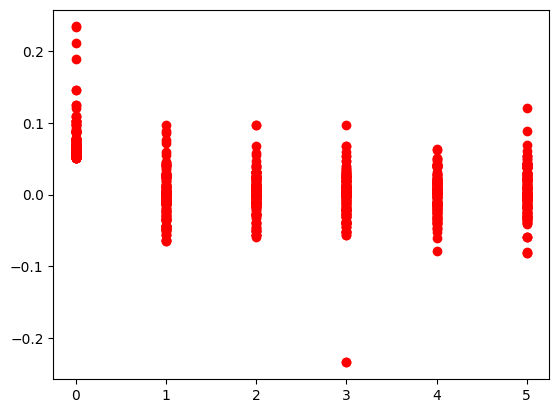

In [8]:
import matplotlib.pyplot as plt

for i in range(6,11):
    condition = (gainers[f"{i} Day Change"] > 0.05) & (gainers["Bottom F1W Gainers"])
    for j in range(0,6):
        plt.scatter([j for _ in range(len(gainers.loc[condition]))], gainers.loc[condition, f"{j} Day Change After Major Loss"], color='red')

plt.show()

In [9]:
gainers["3 Day Change After Major Loss"].count()

np.int64(146)

In [10]:
losers = market[market["Loser"] == True]


for i in range(5,11):
    condition = (losers[f"{i} Day Change"] > 0.05)  & (losers["Bottom F1W Losers"])
    for j in range(0,6):
        losers.loc[condition, f"{j} Day Change After Major Loss"] = losers.loc[condition, f"{i+j} Day Change"]

C:\Users\luis\AppData\Local\Temp\ipykernel_28900\2881359843.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  losers.loc[condition, f"{j} Day Change After Major Loss"] = losers.loc[condition, f"{i+j} Day Change"]
C:\Users\luis\AppData\Local\Temp\ipykernel_28900\2881359843.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  losers.loc[condition, f"{j} Day Change After Major Loss"] = losers.loc[condition, f"{i+j} Day Change"]
C:\Users\luis\AppData\Local\Temp\ipykernel_28900\2881359843.py:7: SettingWithCopyW

In [11]:
print(losers["1 Day Change After Major Loss"].mean())
print(losers["2 Day Change After Major Loss"].mean())
print(losers["3 Day Change After Major Loss"].mean())
print(losers["4 Day Change After Major Loss"].mean())
print(losers["5 Day Change After Major Loss"].mean())

0.00011664465299906722
0.000934270089936793
-0.0001633485569447613
0.001443679076476914
-0.0025169942407254685


In [12]:
losers["5 Day Change After Major Loss"].count()

np.int64(166)

In [13]:
for i in range(1,6):
    print(losers[losers[f"{i} Day Change After Major Loss"] > 0].count()[f"{i} Day Change After Major Loss"])
    print(losers[losers[f"{i} Day Change After Major Loss"] < 0].count()[f"{i} Day Change After Major Loss"])
    print(losers[losers[f"{i} Day Change After Major Loss"] > 0].count()[f"{i} Day Change After Major Loss"] / losers[f"{i} Day Change After Major Loss"].count())
    print(losers[f"{i} Day Change After Major Loss"].count(), "\n")

83
82
0.5
166 

91
74
0.5481927710843374
166 

91
75
0.5481927710843374
166 

97
68
0.5843373493975904
166 

78
88
0.46987951807228917
166 



'!dlroW olleH'